# Accuracy by task type

In [11]:
import pandas as pd
all_traj = pd.read_csv('output/all_traj.csv')
all_traj['Tasktype1'] = all_traj['Task'].str.split('_',n=1,expand=True)[0]
all_traj['Tasktype2'] = all_traj['Task'].str.split('_',expand=True)[1]
all_traj

,Respondent,Task,Run,IsCorrect,Trajectory,SemanticTraj,Tasktype1,Tasktype2
0,gemini-3-pro,associate_attribute_1,1,0,"['G1', 'G2', 'H1', 'H2', 'H1', 'H2', 'C6', 'C5...","['L', 'L', 'K', 'K', 'K', 'K', 'A', 'T', 'A', ...",associate,attribute
1,gemini-3-pro,associate_attribute_1,10,1,"['F1', 'G1', 'H1', 'H1', 'E2', 'C8', 'F2', 'G2...","['L', 'L', 'K', 'K', 'M', 'T', 'L', 'L', 'K', ...",associate,attribute
2,gemini-3-pro,associate_attribute_1,11,0,"['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8...","['Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'L', ...",associate,attribute
3,gemini-3-pro,associate_attribute_1,12,1,"['C6', 'F1', 'H1', 'H1', 'F2', 'H2', 'H2', 'C6...","['A', 'L', 'K', 'K', 'L', 'K', 'K', 'A', 'T', ...",associate,attribute
4,gemini-3-pro,associate_attribute_1,13,1,"['C6', 'C6', 'B6', 'C5', 'D6', 'F1', 'H1', 'H1...","['A', 'A', 'A', 'T', 'T', 'L', 'K', 'K', 'A', ...",associate,attribute
...,...,...,...,...,...,...,...,...
2980,qwen3-vl-8b-thinking,rank_time_1,5,0,"['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'E7', 'F7...","['Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'T', 'T', 'M', ...",rank,time
2981,qwen3-vl-8b-thinking,rank_time_1,6,0,"['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'E7', 'E6...","['Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'T', 'A', 'A', ...",rank,time
2982,qwen3-vl-8b-thinking,rank_time_1,7,0,"['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'F6', 'F7...","['Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'A', 'T', 'T', ...",rank,time
2983,qwen3-vl-8b-thinking,rank_time_1,8,0,"['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'E7', 'A7...","['Q', 'Q', 'Q', 'Q', 'Q', 'Q', 'T', 'Q', 'T', ...",rank,time


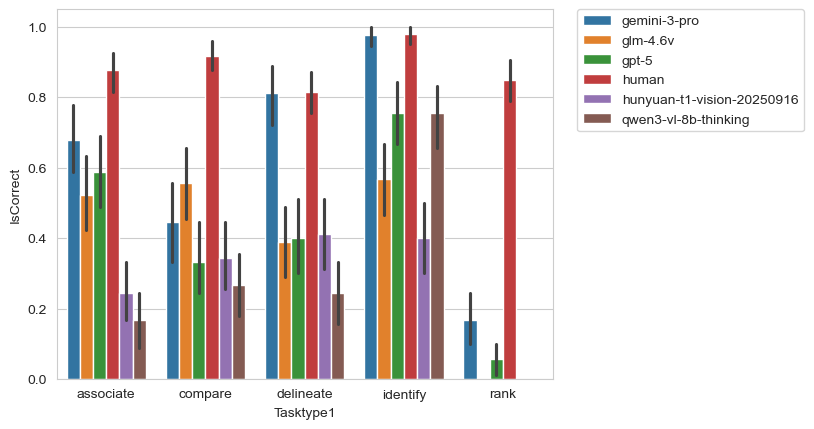

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(data=all_traj,x='Tasktype1',y='IsCorrect',hue='Respondent')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.show()

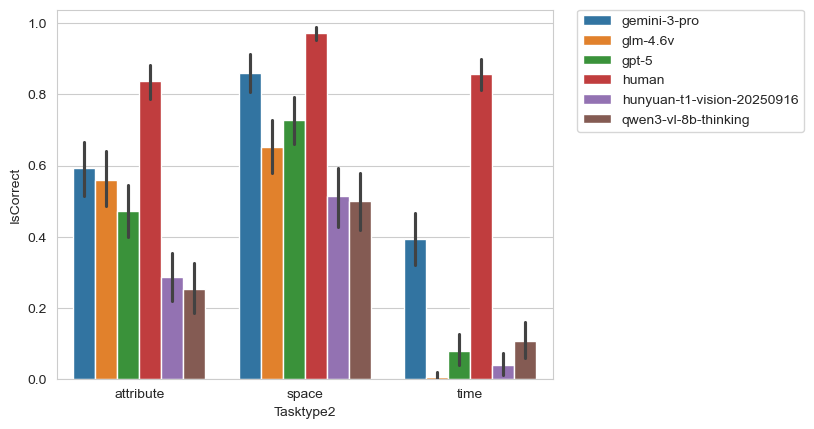

In [46]:
sns.barplot(data=all_traj,x='Tasktype2',y='IsCorrect',hue='Respondent')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.show()

# Local Pattern and statistics

In [13]:
import pandas as pd
import numpy as np
all_code = pd.read_csv('data/all_code.csv')
all_code['SemanticCode2'] = all_code['SemanticCode'].shift(-1)
all_code['SemanticCode3'] = all_code['SemanticCode'].shift(-2)
all_code['LocalPattern'] = all_code['SemanticCode'] + all_code['SemanticCode2'] + all_code['SemanticCode3']
# Remove the local patterns in the two rows preceding each row with Index equal to 1
index1 = np.array(all_code[all_code['Index']==1].index[1:]) -1  
index2 = index1 -1
df_local_pattern = all_code[['Run','IsCorrect','Task','Respondent','Index','LocalPattern']].drop(index1)
df_local_pattern = df_local_pattern.drop(index2)
df_local_pattern.reset_index(drop=True, inplace=True)
# Remove the last two rows as well
df_local_pattern = df_local_pattern.drop(len(df_local_pattern)-1)
df_local_pattern = df_local_pattern.drop(len(df_local_pattern)-1)
df_local_pattern

,Run,IsCorrect,Task,Respondent,Index,LocalPattern
0,1,1,associate_attribute_1,gpt-5,1,AKK
1,1,1,associate_attribute_1,gpt-5,2,KKA
2,1,1,associate_attribute_1,gpt-5,3,KAA
3,1,1,associate_attribute_1,gpt-5,4,AAT
4,1,1,associate_attribute_1,gpt-5,5,ATT
...,...,...,...,...,...,...
119620,P52,1,rank_time_1,human,82,TAA
119621,P52,1,rank_time_1,human,83,AAQ
119622,P52,1,rank_time_1,human,84,AQQ
119623,P52,1,rank_time_1,human,85,QQQ


In [14]:
# Assign each three-letter sequence to a local pattern:
def assign_local_pattern(input_string):
    string_set = set(input_string)
    if input_string=='QQQ': 
        return 'QI' # question interpretation
    elif {'Q','M'}.issubset(string_set) or {'Q','T'}.issubset(string_set):
        return 'QD' # question decoding
    elif {'Q','K'}.issubset(string_set) or {'Q','L'}.issubset(string_set):
        return 'IO' # information overview
    elif input_string=='KKK' or (
            'K' in string_set and len({'L','M','T'}&string_set) > 0): # At least one of L/M/T is in the string, i.e., the intersection is nonempty
        return 'KD' # key-legend decoding
    elif input_string=='LLL' or (
            'L' in string_set and len({'M','T'}&string_set)>0):
        return 'LU' # legend usage
    elif input_string=='MMM' or ({'M','T'}.issubset(string_set)): 
        return 'SN' # spatial navigation
    elif input_string=='TTT':
        return 'TC' # target comparison
    elif 'A' in string_set:
        return 'AD' # answer decision
    else:
        return None
    
# Define a function with error handling
def safe_convert(x):
    try:
        return assign_local_pattern(x)
    except:
        return None
    
safe_convert('MTA')
df_local_pattern['LocalPatternName'] = df_local_pattern['LocalPattern'].apply(safe_convert)

In [15]:
df_local_pattern.to_csv('output/local_pattern.csv', index=False)
df_local_pattern

,Run,IsCorrect,Task,Respondent,Index,LocalPattern,LocalPatternName
0,1,1,associate_attribute_1,gpt-5,1,AKK,AD
1,1,1,associate_attribute_1,gpt-5,2,KKA,AD
2,1,1,associate_attribute_1,gpt-5,3,KAA,AD
3,1,1,associate_attribute_1,gpt-5,4,AAT,AD
4,1,1,associate_attribute_1,gpt-5,5,ATT,AD
...,...,...,...,...,...,...,...
119620,P52,1,rank_time_1,human,82,TAA,AD
119621,P52,1,rank_time_1,human,83,AAQ,AD
119622,P52,1,rank_time_1,human,84,AQQ,AD
119623,P52,1,rank_time_1,human,85,QQQ,QI


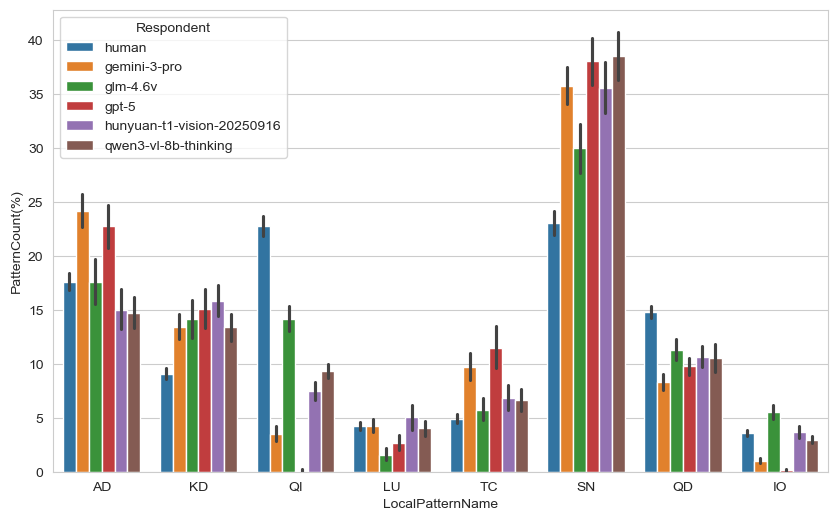

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
patterns = ['AD', 'KD', 'QI', 'LU', 'TC', 'SN', 'QD', 'IO']
df_local_pattern['LocalPatternName'] = pd.Categorical(df_local_pattern['LocalPatternName'], categories=patterns)

data_human = df_local_pattern[df_local_pattern['Respondent']=='human'].reset_index(drop=True)
data_human = data_human.groupby(['Respondent','Task','Run','LocalPatternName'], observed=False).size().reset_index()
data_ai = df_local_pattern[df_local_pattern['Respondent']!='human'].reset_index(drop=True)
data_ai = data_ai.groupby(['Respondent','Task','Run','LocalPatternName'], observed=False).size().reset_index()
data = pd.concat([data_human, data_ai], ignore_index=True)

data = data.rename(columns={0:'PatternCount'})
sum = data.groupby(['Respondent','Task','Run'])['PatternCount'].sum().reset_index().rename(columns={'PatternCount':'PatternCountSum'})
data = data.merge(sum, on=['Respondent','Task','Run'])
data['PatternCount(%)'] = data['PatternCount']/data['PatternCountSum'] * 100


plt.figure(figsize=(10,6))
sns.barplot(data=data,x='LocalPatternName',y='PatternCount(%)',hue='Respondent')
plt.show()
# data
# sum

In [18]:
respondents = data['Respondent'].unique().tolist()
for respondent1 in respondents:
    i = 1
    respondent2 = respondents[-1]
    while respondent1 != respondent2:
        df = data[(data['Respondent']==respondent1) | (data['Respondent']==respondent2)].reset_index(drop=True)
        pivot_df = df.pivot_table(index=['Respondent','Task','Run'], columns='LocalPatternName', values='PatternCount(%)',
                                  observed=False).reset_index()
        pivot_df.to_csv(f'output/for_spss/pattern/{respondent1}_{respondent2}.csv', index=False)
        i += 1
        respondent2 = respondents[-i]


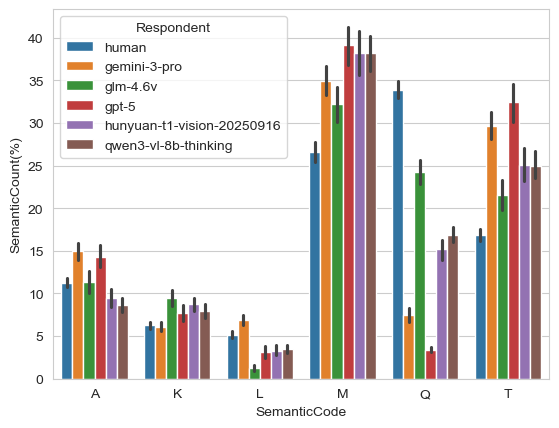

In [19]:
import pandas as pd
all_code = pd.read_csv('data/all_code.csv')
aois = ['A', 'K', 'L', 'M', 'Q', 'T']
all_code['SemanticCode'] = pd.Categorical(all_code['SemanticCode'], categories=aois)

data_human = all_code[all_code['Respondent']=='human'].reset_index(drop=True)
data_human = data_human.groupby(['Respondent','Task','Run','SemanticCode'], observed=False).size().reset_index()
data_ai = all_code[all_code['Respondent']!='human'].reset_index(drop=True)
data_ai = data_ai.groupby(['Respondent','Task','Run','SemanticCode'], observed=False).size().reset_index()
data = pd.concat([data_human, data_ai], ignore_index=True)
data = data.rename(columns={0:'SemanticCount'})

sum = data.groupby(['Respondent','Task','Run'])['SemanticCount'].sum().reset_index().rename(columns={'SemanticCount':'SemanticCountSum'})
data = data.merge(sum, on=['Respondent','Task','Run'])
data['SemanticCount(%)'] = data['SemanticCount']/data['SemanticCountSum'] *100
data
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(data=data,x='SemanticCode',y='SemanticCount(%)',hue='Respondent')
# plt.savefig('semantic.png', dpi=300)
plt.show()

In [21]:
respondents = data['Respondent'].unique().tolist()
for respondent1 in respondents:
    i = 1
    respondent2 = respondents[-1]
    while respondent1 != respondent2:
        df = data[(data['Respondent']==respondent1) | (data['Respondent']==respondent2)].reset_index(drop=True)
        pivot_df = df.pivot_table(index=['Respondent','Task','Run'], columns='SemanticCode', values='SemanticCount(%)',
                                  observed=False).reset_index()
        pivot_df.to_csv(f'output/for_spss/semantic/{respondent1}_{respondent2}.csv', index=False)
        i += 1
        respondent2 = respondents[-i]

In [22]:
import pandas as pd
all_code = pd.read_csv('data/all_code.csv')
aois = ['A', 'K', 'L', 'M', 'Q', 'T']
all_code['SemanticCode'] = pd.Categorical(all_code['SemanticCode'], categories=aois)
all_code
data_human = all_code[all_code['Respondent']=='human'].reset_index(drop=True)
data_human = data_human.groupby(['Respondent','Task','Run','SemanticCode'], observed=False).size().reset_index()
data_ai = all_code[all_code['Respondent']!='human'].reset_index(drop=True)
data_ai = data_ai.groupby(['Respondent','Task','Run','SemanticCode'], observed=False).size().reset_index()
data = pd.concat([data_human, data_ai], ignore_index=True)
data = data.rename(columns={0:'SemanticCount'})

temp = all_code[['Respondent','Task','Run','IsCorrect']].drop_duplicates().reset_index(drop=True)
data = data.merge(temp, on=['Respondent','Task','Run'])

data_1 = data[data['IsCorrect']==1].reset_index(drop=True)
data_0 = data[data['IsCorrect']==0].reset_index(drop=True)

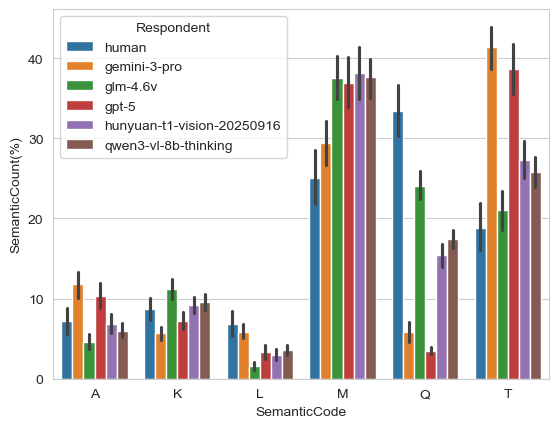

In [23]:
sum = data_0.groupby(['Respondent','Task','Run'])['SemanticCount'].sum().reset_index().rename(columns={'SemanticCount':'SemanticCountSum'})
data_0 = data_0.merge(sum, on=['Respondent','Task','Run'])
data_0['SemanticCount(%)'] = data_0['SemanticCount']/data_0['SemanticCountSum'] *100
data_0
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(data=data_0,x='SemanticCode',y='SemanticCount(%)',hue='Respondent')
plt.show()

In [24]:
respondents = data_0['Respondent'].unique().tolist()
for respondent1 in respondents:
    i = 1
    respondent2 = respondents[-1]
    while respondent1 != respondent2:
        df = data_0[(data_0['Respondent']==respondent1) | (data_0['Respondent']==respondent2)].reset_index(drop=True)
        pivot_df = df.pivot_table(index=['Respondent','Task','Run'], columns='SemanticCode', values='SemanticCount(%)',
                                  observed=False).reset_index()
        pivot_df.to_csv(f'output/for_spss/semantic_0/{respondent1}_{respondent2}.csv', index=False)
        i += 1
        respondent2 = respondents[-i]

OSError: Cannot save file into a non-existent directory: 'output\for_spss\semantic_0'

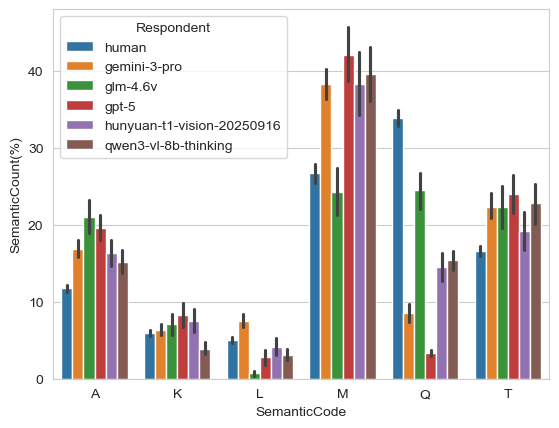

In [62]:
sum = data_1.groupby(['Respondent','Task','Run'])['SemanticCount'].sum().reset_index().rename(columns={'SemanticCount':'SemanticCountSum'})
data_1 = data_1.merge(sum, on=['Respondent','Task','Run'])
data_1['SemanticCount(%)'] = data_1['SemanticCount']/data_1['SemanticCountSum'] *100
# data_1
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(data=data_1,x='SemanticCode',y='SemanticCount(%)',hue='Respondent')
plt.show()

In [64]:
respondents = data_1['Respondent'].unique().tolist()
for respondent1 in respondents:
    i = 1
    respondent2 = respondents[-1]
    while respondent1 != respondent2:
        df = data_1[(data_1['Respondent']==respondent1) | (data_1['Respondent']==respondent2)].reset_index(drop=True)
        pivot_df = df.pivot_table(index=['Respondent','Task','Run'], columns='SemanticCode', values='SemanticCount(%)',
                                  observed=False).reset_index()
        pivot_df.to_csv(f'output/for_spss/semantic_1/{respondent1}_{respondent2}.csv', index=False)
        i += 1
        respondent2 = respondents[-i]

# Transition matrix ↓

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
local_pattern = pd.read_csv('output/local_pattern.csv')
local_pattern['NextPattern'] = local_pattern['LocalPatternName'].shift(-1)
# Set the next pattern in the row preceding each row with Index equal to 1 to empty
index1 = np.array(local_pattern[local_pattern['Index']==1].index[1:]) -1  # Use a NumPy array to subtract one from all indices
local_pattern.loc[index1, 'NextPattern'] = None
local_pattern

,Run,IsCorrect,Task,Respondent,Index,LocalPattern,LocalPatternName,NextPattern
0,1,1,associate_attribute_1,gpt-5,1,AKK,AD,AD
1,1,1,associate_attribute_1,gpt-5,2,KKA,AD,AD
2,1,1,associate_attribute_1,gpt-5,3,KAA,AD,AD
3,1,1,associate_attribute_1,gpt-5,4,AAT,AD,AD
4,1,1,associate_attribute_1,gpt-5,5,ATT,AD,KD
...,...,...,...,...,...,...,...,...
119620,P52,1,rank_time_1,human,82,TAA,AD,AD
119621,P52,1,rank_time_1,human,83,AAQ,AD,AD
119622,P52,1,rank_time_1,human,84,AQQ,AD,QI
119623,P52,1,rank_time_1,human,85,QQQ,QI,QI


In [26]:

def draw_transfer_matrix(df, name):
    plt.clf()
    plt.cla()
    patterns = ['AD', 'KD', 'QI', 'LU', 'TC', 'SN', 'QD', 'IO']
    df['NextPattern'] = pd.Categorical(df['NextPattern'], categories=patterns)
    df['LocalPatternName'] = pd.Categorical(df['LocalPatternName'], categories=patterns)
    
    data = df[['LocalPatternName','NextPattern']].groupby(['LocalPatternName','NextPattern'],observed=False).size().reset_index()
    data.rename(columns={0:'NextPatternCount'}, inplace=True)
    # Remove transitions from a code to itself
    ix = (data[data['LocalPatternName']==data['NextPattern']]).index
    data.loc[ix, 'NextPatternCount'] = None
    
    temp = data.groupby('LocalPatternName')['NextPatternCount'].sum().reset_index()
    temp.rename(columns={'NextPatternCount':'PatternCount'}, inplace=True)
    data = data.merge(temp, on='LocalPatternName', how='left')
    data['NextPatternRate'] = data['NextPatternCount']/data['PatternCount']
    data
    pivot_data = data.pivot_table(index='LocalPatternName', columns='NextPattern', values='NextPatternRate', observed=False)
    
    ax = sns.heatmap(pivot_data, annot=True, cmap='YlGnBu', vmin=0, vmax=1, fmt=".2f")
    ax.grid(False)
    plt.yticks(rotation=0)
    ax.xaxis.tick_top() # x-axis on top
    ax.xaxis.set_label_position('top')
    plt.tick_params(top=False)
    plt.title(f'{name} pattern transfer matrix')
    plt.savefig(f'output/transfer_matrix/pattern/{name}_pattern.png', dpi=300)
    # plt.show()

C:\Users\17475\AppData\Local\Temp\ipykernel_30712\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('LocalPatternName')['NextPatternCount'].sum().reset_index()


FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Desktop\\ai_read\\整理提交代码\\code\\output\\transfer_matrix\\pattern\\all_0_pattern.png'

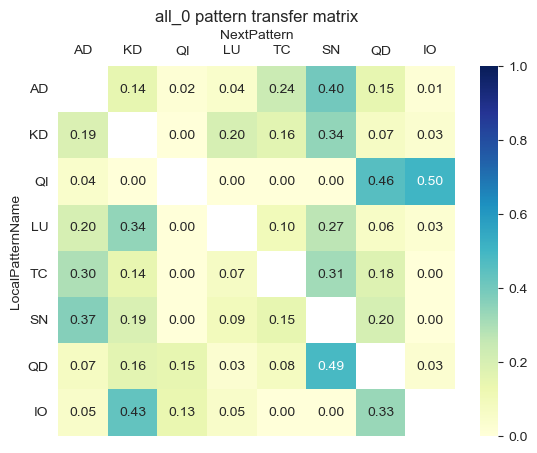

In [27]:
df = local_pattern[local_pattern['IsCorrect']==0].reset_index(drop=True)   # All incorrect responses from all respondents
draw_transfer_matrix(df, 'all_0')
df = local_pattern[local_pattern['IsCorrect']==1].reset_index(drop=True)   # All correct responses from all respondents
draw_transfer_matrix(df, 'all_1')

C:\Users\17475\AppData\Local\Temp\ipykernel_11676\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('LocalPatternName')['NextPatternCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('LocalPatternName')['NextPatternCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current beha

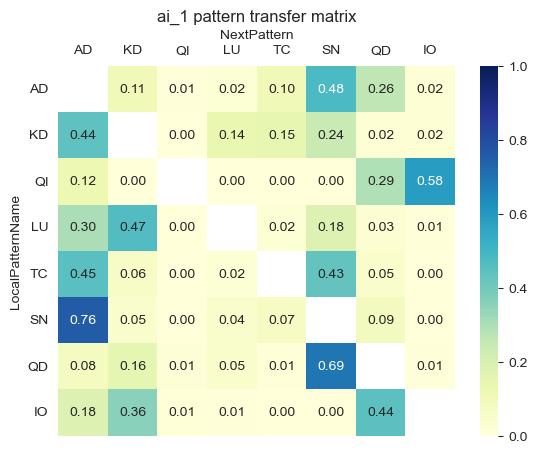

In [72]:

df = local_pattern[local_pattern['Respondent']!='human'].reset_index(drop=True) # All AI models combined
draw_transfer_matrix(df, 'ai')
df = local_pattern[(local_pattern['Respondent']!='human')&(local_pattern['IsCorrect']==0)].reset_index(drop=True)   # All incorrect responses
draw_transfer_matrix(df, 'ai_0')
df = local_pattern[(local_pattern['Respondent']!='human')&(local_pattern['IsCorrect']==1)].reset_index(drop=True)   # All correct responses
draw_transfer_matrix(df, 'ai_1')

C:\Users\17475\AppData\Local\Temp\ipykernel_11676\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('LocalPatternName')['NextPatternCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('LocalPatternName')['NextPatternCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\4280670539.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current beha

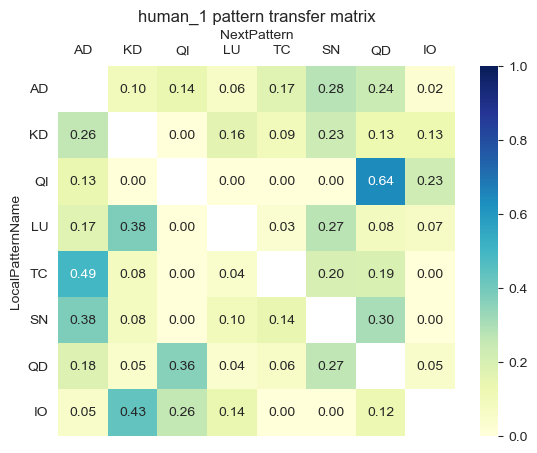

In [73]:

for respondent in local_pattern['Respondent'].unique():
    df = local_pattern[local_pattern['Respondent']==respondent].reset_index(drop=True)
    draw_transfer_matrix(df, respondent)
    df = local_pattern[(local_pattern['Respondent']==respondent)&(local_pattern['IsCorrect']==0)].reset_index(drop=True)
    draw_transfer_matrix(df, f'{respondent}_0')
    df = local_pattern[(local_pattern['Respondent']==respondent)&(local_pattern['IsCorrect']==1)].reset_index(drop=True)
    draw_transfer_matrix(df, f'{respondent}_1')

In [74]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
all_code = pd.read_csv('data/all_code.csv')
all_code['NextSemantic'] = all_code['SemanticCode'].shift(-1)
# Set NextSemantic in the row preceding each row with Index equal to 1 to empty
index1 = np.array(all_code[all_code['Index']==1].index[1:]) -1  # Use a NumPy array to subtract one from all indices
all_code.loc[index1, 'NextSemantic'] = None
all_code

,Run,GridAoi,IsCorrect,Task,Respondent,Index,SemanticCode,NextSemantic
0,1,C6,1,associate_attribute_1,gpt-5,1,A,K
1,1,H1,1,associate_attribute_1,gpt-5,2,K,K
2,1,H2,1,associate_attribute_1,gpt-5,3,K,A
3,1,C6,1,associate_attribute_1,gpt-5,4,A,A
4,1,C6,1,associate_attribute_1,gpt-5,5,A,T
...,...,...,...,...,...,...,...,...
125590,P52,F6,1,rank_time_1,human,84,A,Q
125591,P52,A1,1,rank_time_1,human,85,Q,Q
125592,P52,A1,1,rank_time_1,human,86,Q,Q
125593,P52,A2,1,rank_time_1,human,87,Q,Q


In [75]:
def draw_transfer_matrix(df, name):
    plt.clf()
    plt.cla()
    aois = ['A', 'K', 'L', 'M', 'Q', 'T']
    df['NextSemantic'] = pd.Categorical(df['NextSemantic'], categories=aois)
    df['SemanticCode'] = pd.Categorical(df['SemanticCode'], categories=aois)
    
    data = df[['SemanticCode','NextSemantic']].groupby(['SemanticCode','NextSemantic'],observed=False).size().reset_index()
    data.rename(columns={0:'NextSemanticCount'}, inplace=True)
    # Remove transitions from a code to itself
    ix = (data[data['SemanticCode']==data['NextSemantic']]).index
    data.loc[ix, 'NextSemanticCount'] = None
    
    temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()
    temp.rename(columns={'NextSemanticCount':'SemanticCount'}, inplace=True)
    data = data.merge(temp, on='SemanticCode', how='left')
    data['NextSemanticRate'] = data['NextSemanticCount']/data['SemanticCount']
    data
    pivot_data = data.pivot_table(index='SemanticCode', columns='NextSemantic', values='NextSemanticRate', observed=False)
    
    ax = sns.heatmap(pivot_data, annot=True, annot_kws={'fontsize': 15}, cmap='YlGnBu', vmin=0, vmax=1, fmt=".2f")

    ax.tick_params(axis='both', labelsize=15)# X- and Y-axis tick font size
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=15)   # Colorbar tick font size
    ax.grid(False)
    plt.yticks(rotation=0)
    ax.xaxis.tick_top() # x axis on top
    ax.xaxis.set_label_position('top')
    plt.tick_params(top=False)
    plt.title(f'{name} semantic code transfer matrix')
    
    plt.savefig(f'output/transfer_matrix/semantic/{name}_semantic.png', dpi=300, bbox_inches='tight')
    # plt.show()

C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()


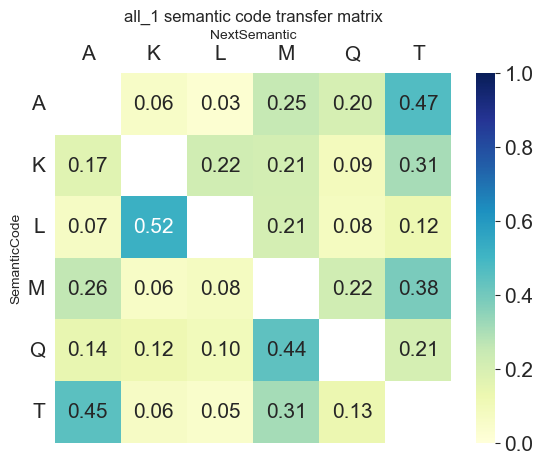

In [77]:
df = all_code[all_code['IsCorrect']==0].reset_index(drop=True)   # All incorrect responses
draw_transfer_matrix(df, 'all_0')
df = all_code[all_code['IsCorrect']==1].reset_index(drop=True)   # All correct responses
draw_transfer_matrix(df, 'all_1')

C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or o

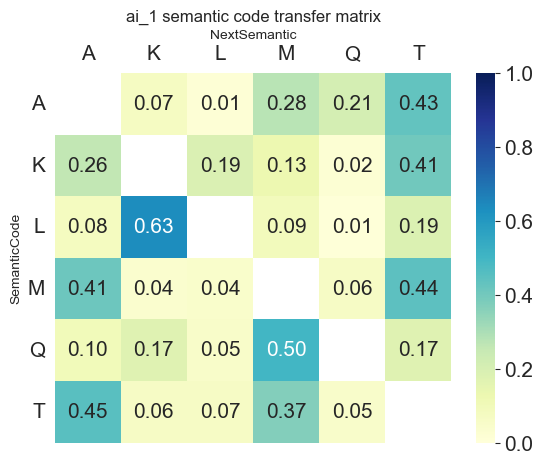

In [78]:
df = all_code[all_code['Respondent']!='human'].reset_index(drop=True) # All AI models combined
draw_transfer_matrix(df, 'ai')
df = all_code[(all_code['Respondent']!='human')&(all_code['IsCorrect']==0)].reset_index(drop=True)   # All incorrect responses
draw_transfer_matrix(df, 'ai_0')
df = all_code[(all_code['Respondent']!='human')&(all_code['IsCorrect']==1)].reset_index(drop=True)   # All correct responses
draw_transfer_matrix(df, 'ai_1')

C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp = data.groupby('SemanticCode')['NextSemanticCount'].sum().reset_index()
C:\Users\17475\AppData\Local\Temp\ipykernel_11676\719280265.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or o

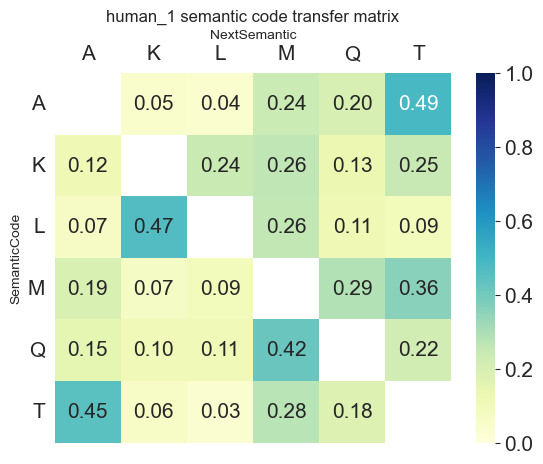

In [79]:
for respondent in all_code['Respondent'].unique():
    df = all_code[all_code['Respondent']==respondent].reset_index(drop=True)
    draw_transfer_matrix(df, respondent)
    df = all_code[(all_code['Respondent']==respondent)&(all_code['IsCorrect']==0)].reset_index(drop=True)
    draw_transfer_matrix(df, f'{respondent}_0')
    df = all_code[(all_code['Respondent']==respondent)&(all_code['IsCorrect']==1)].reset_index(drop=True)
    draw_transfer_matrix(df, f'{respondent}_1')

# Boxenplot of the overall distribution of distances between respondents ↓

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
traj_compare = pd.read_csv('output/traj_compare.csv')
traj_compare_human = pd.read_csv('output/traj_compare_human.csv')
traj_compare_ai = pd.read_csv('output/traj_compare_ai.csv')

data1 = traj_compare_human[['Task','Levenshtein','Frdist','MultiVecShape','MultiVecLen','MultiVecPosi','MultiVecDirec']].reset_index(drop=True)
data1['Cato'] = 'human_human'

data2 = traj_compare[['Model','Task','Levenshtein','Frdist','MultiVecShape','MultiVecLen','MultiVecPosi','MultiVecDirec']].reset_index(drop=True)
data2['Cato'] = 'model_human'
data2.drop(columns='Model', inplace=True)
data2

,Task,Levenshtein,Frdist,MultiVecShape,MultiVecLen,MultiVecPosi,MultiVecDirec,Cato
0,associate_attribute_1,68,6.082763,0.938109,0.816034,0.936283,0.711580,model_human
1,associate_attribute_1,56,6.324555,0.937500,0.663099,0.936283,0.625000,model_human
2,associate_attribute_1,66,6.082763,0.937500,0.673803,0.908551,0.750000,model_human
3,associate_attribute_1,112,6.082763,0.942122,0.500000,0.938717,0.782106,model_human
4,associate_attribute_1,63,6.082763,0.937500,0.500000,0.938717,0.754869,model_human
...,...,...,...,...,...,...,...,...
110245,rank_time_1,71,6.403124,0.945527,0.836901,0.938717,0.754869,model_human
110246,rank_time_1,90,9.219544,0.945527,0.663099,0.938717,0.836013,model_human
110247,rank_time_1,72,7.071068,0.945527,0.614200,0.938717,0.782106,model_human
110248,rank_time_1,199,7.211103,0.938717,0.500000,0.938717,0.773652,model_human


In [29]:
traj_compare_ai['Model1'] = traj_compare_ai['Model_Run1'].str.split('_', n=1, expand=True)[0]
traj_compare_ai['Model2'] = traj_compare_ai['Model_Run2'].str.split('_', n=1, expand=True)[0]
traj_compare_ai

temp = traj_compare_ai[['Model1','Model2','Task','Levenshtein','Frdist','MultiVecShape','MultiVecLen','MultiVecPosi','MultiVecDirec']].reset_index(drop=True)
data3 = temp[temp['Model1']==temp['Model2']][['Task','Levenshtein','Frdist','MultiVecShape','MultiVecLen','MultiVecPosi','MultiVecDirec']].reset_index(drop=True)
data3['Cato'] = 'within_model'
data3

,Task,Levenshtein,Frdist,MultiVecShape,MultiVecLen,MultiVecPosi,MultiVecDirec,Cato
0,associate_attribute_1,28,5.000000,0.937500,0.768703,0.907106,0.816152,within_model
1,associate_attribute_1,25,7.071068,0.969359,0.904315,0.945527,0.875000,within_model
2,associate_attribute_1,22,6.403124,0.937500,0.776911,0.936283,0.875000,within_model
3,associate_attribute_1,28,6.403124,0.937500,0.795167,0.907106,0.773652,within_model
4,associate_attribute_1,22,4.123106,0.945527,0.836901,0.938717,0.914885,within_model
...,...,...,...,...,...,...,...,...
32620,rank_time_1,43,4.472136,0.969359,0.836901,0.983947,0.559924,within_model
32621,rank_time_1,14,2.000000,0.969359,0.908309,0.983947,0.891053,within_model
32622,rank_time_1,42,4.472136,0.937500,0.836901,0.961013,0.553614,within_model
32623,rank_time_1,29,5.000000,0.938717,0.836901,0.946770,0.875000,within_model


In [30]:
data4 = temp[temp['Model1']!=temp['Model2']][['Task','Levenshtein','Frdist','MultiVecShape','MultiVecLen','MultiVecPosi','MultiVecDirec']].reset_index(drop=True)
data4['Cato'] = 'between_model'
data4

,Task,Levenshtein,Frdist,MultiVecShape,MultiVecLen,MultiVecPosi,MultiVecDirec,Cato
0,associate_attribute_1,23,6.708204,0.918007,0.663099,0.936283,0.650934,between_model
1,associate_attribute_1,23,6.708204,0.937500,0.748794,0.945527,0.876217,between_model
2,associate_attribute_1,25,6.708204,0.937500,0.941002,0.952336,0.752435,between_model
3,associate_attribute_1,24,6.708204,0.937500,0.836901,0.936283,0.667464,between_model
4,associate_attribute_1,26,6.082763,0.886826,0.768703,0.812872,0.731749,between_model
...,...,...,...,...,...,...,...,...
134995,rank_time_1,21,3.000000,0.945527,1.000000,0.997565,0.875000,between_model
134996,rank_time_1,24,5.385165,0.969359,0.836901,0.983947,0.875000,between_model
134997,rank_time_1,32,4.123106,0.918007,0.836901,0.961013,0.875000,between_model
134998,rank_time_1,34,4.123106,0.938717,0.816479,0.986382,0.673159,between_model


In [31]:

df = pd.DataFrame(pd.concat([data1, data2, data3, data4], axis=0))
df['Levenshtein'] = 1- df['Levenshtein']/df['Levenshtein'].max()
df['Frdist'] = 1- df['Frdist']/df['Frdist'].max()
df = df.drop_duplicates()

df = df.melt(id_vars=['Task','Cato'], var_name='Alg')
df.rename(columns={'value':'Value'}, inplace=True)
df

,Task,Cato,Alg,Value
0,associate_attribute_1,human_human,Levenshtein,0.813814
1,associate_attribute_1,human_human,Levenshtein,0.804805
2,associate_attribute_1,human_human,Levenshtein,0.714715
3,associate_attribute_1,human_human,Levenshtein,0.795796
4,associate_attribute_1,human_human,Levenshtein,0.762763
...,...,...,...,...
1676233,rank_time_1,between_model,MultiVecDirec,0.875000
1676234,rank_time_1,between_model,MultiVecDirec,0.875000
1676235,rank_time_1,between_model,MultiVecDirec,0.875000
1676236,rank_time_1,between_model,MultiVecDirec,0.673159


In [94]:
## [Run this cell only when statistical testing is needed]========================


temp = df[df['Alg']=='Levenshtein'].reset_index(drop=True)

# col1 = 'within_model'
# col2 = 'between_model'
# temp = temp[(temp['Cato']==col1) | (temp['Cato']==col2)]
# # temp
# from scipy.stats import mannwhitneyu
# 
# a = temp[temp['Cato'] == col1]['Value'].dropna()
# b = temp[temp['Cato'] == col2]['Value'].dropna()

# Normality test
def examine(data):
    from scipy.stats import shapiro
    stat, p = shapiro(data)
    print(f'Statistic W = {stat:.4f}')
    print(f'p-value = {p:.6f}')
    if p > 0.05:
        print("No significant deviation from normality detected")
    else:
        print("Significant deviation from normality detected")

# Paired-samples t-test
def pair_t(data):
    import pandas as pd
    from scipy.stats import ttest_rel, shapiro
    from statsmodels.stats.multitest import multipletests
    from itertools import combinations
    
    # Mean similarity of the four groups for each task
    df_test = data.groupby(['Task', 'Cato'])['Value'].mean().unstack()
    
    results = []
    
    for a, b in combinations(df_test.columns, 2):
        paired = df_test[[a, b]].dropna()
    
        # Check normality of paired differences
        diff = paired[a] - paired[b]
        normal_p = shapiro(diff).pvalue
    
        # Paired-samples t-test
        t, p = ttest_rel(paired[a], paired[b])
    
        results.append({
            'Group1': a,
            'Group2': b,
            'n': len(paired),
            'Normal_p': normal_p,
            't': t,
            'p': p
        })
    
    results = pd.DataFrame(results)
    
    # Holm correction for multiple comparisons
    results['p_adjusted'] = multipletests(
        results['p'],
        method='holm'
    )[1]
    print(results)

# wilcoxon
def wilcoxon(data):
    
    import pandas as pd
    from scipy.stats import wilcoxon
    from statsmodels.stats.multitest import multipletests
    from itertools import combinations
    
    # Calculate the mean similarity for each of the four categories per task
    temp = data.groupby(['Task', 'Cato'])['Value'].mean().unstack()
    results = []
    
    # Six pairwise comparisons
    for a, b in combinations(temp.columns, 2):
        paired = temp[[a, b]].dropna()
    
        stat, p = wilcoxon(paired[a], paired[b])
    
        results.append({
            'Group1': a,
            'Group2': b,
            'W': stat,
            'p': p
        })
    
    results = pd.DataFrame(results)
    results
    
    # Holm correction for multiple comparisons
    results['p_adjusted'] = multipletests(
        results['p'],
        method='holm'
    )[1]
    
    print(results)

pair_t(temp)
wilcoxon(temp)



from statsmodels.stats.multitest import multipletests
# Use the six original p-values selected for the final results
p_values = [
    8.504634e-07,
    3.713353e-07,
    1.382402e-10,
    0.000183,
    3.328993e-07,
    1.282781e-07
]
p_adjusted = multipletests(p_values, method='holm')[1]
print('holm: ' ,p_adjusted)
p_adjusted = multipletests(p_values, method='fdr_bh')[1]
print('fdr_bh: ' ,p_adjusted)
# ======================================================

          Group1        Group2   n  Normal_p          t             p  \
0  between_model   human_human  15  0.384694   8.331929  8.504634e-07   
1  between_model   model_human  15  0.429606   8.931861  3.713353e-07   
2  between_model  within_model  15  0.343376 -16.544633  1.382402e-10   
3    human_human   model_human  15  0.011409  -4.070704  1.145890e-03   
4    human_human  within_model  15  0.394536  -9.013198  3.328993e-07   
5    model_human  within_model  15  0.423397  -9.746455  1.282781e-07   

     p_adjusted  
0  1.700927e-06  
1  1.331597e-06  
2  8.294413e-10  
3  1.145890e-03  
4  1.331597e-06  
5  6.413907e-07  
          Group1        Group2    W         p  p_adjusted
0  between_model   human_human  0.0  0.000061    0.000366
1  between_model   model_human  0.0  0.000061    0.000366
2  between_model  within_model  0.0  0.000061    0.000366
3    human_human   model_human  2.0  0.000183    0.000366
4    human_human  within_model  0.0  0.000061    0.000366
5    model_hum

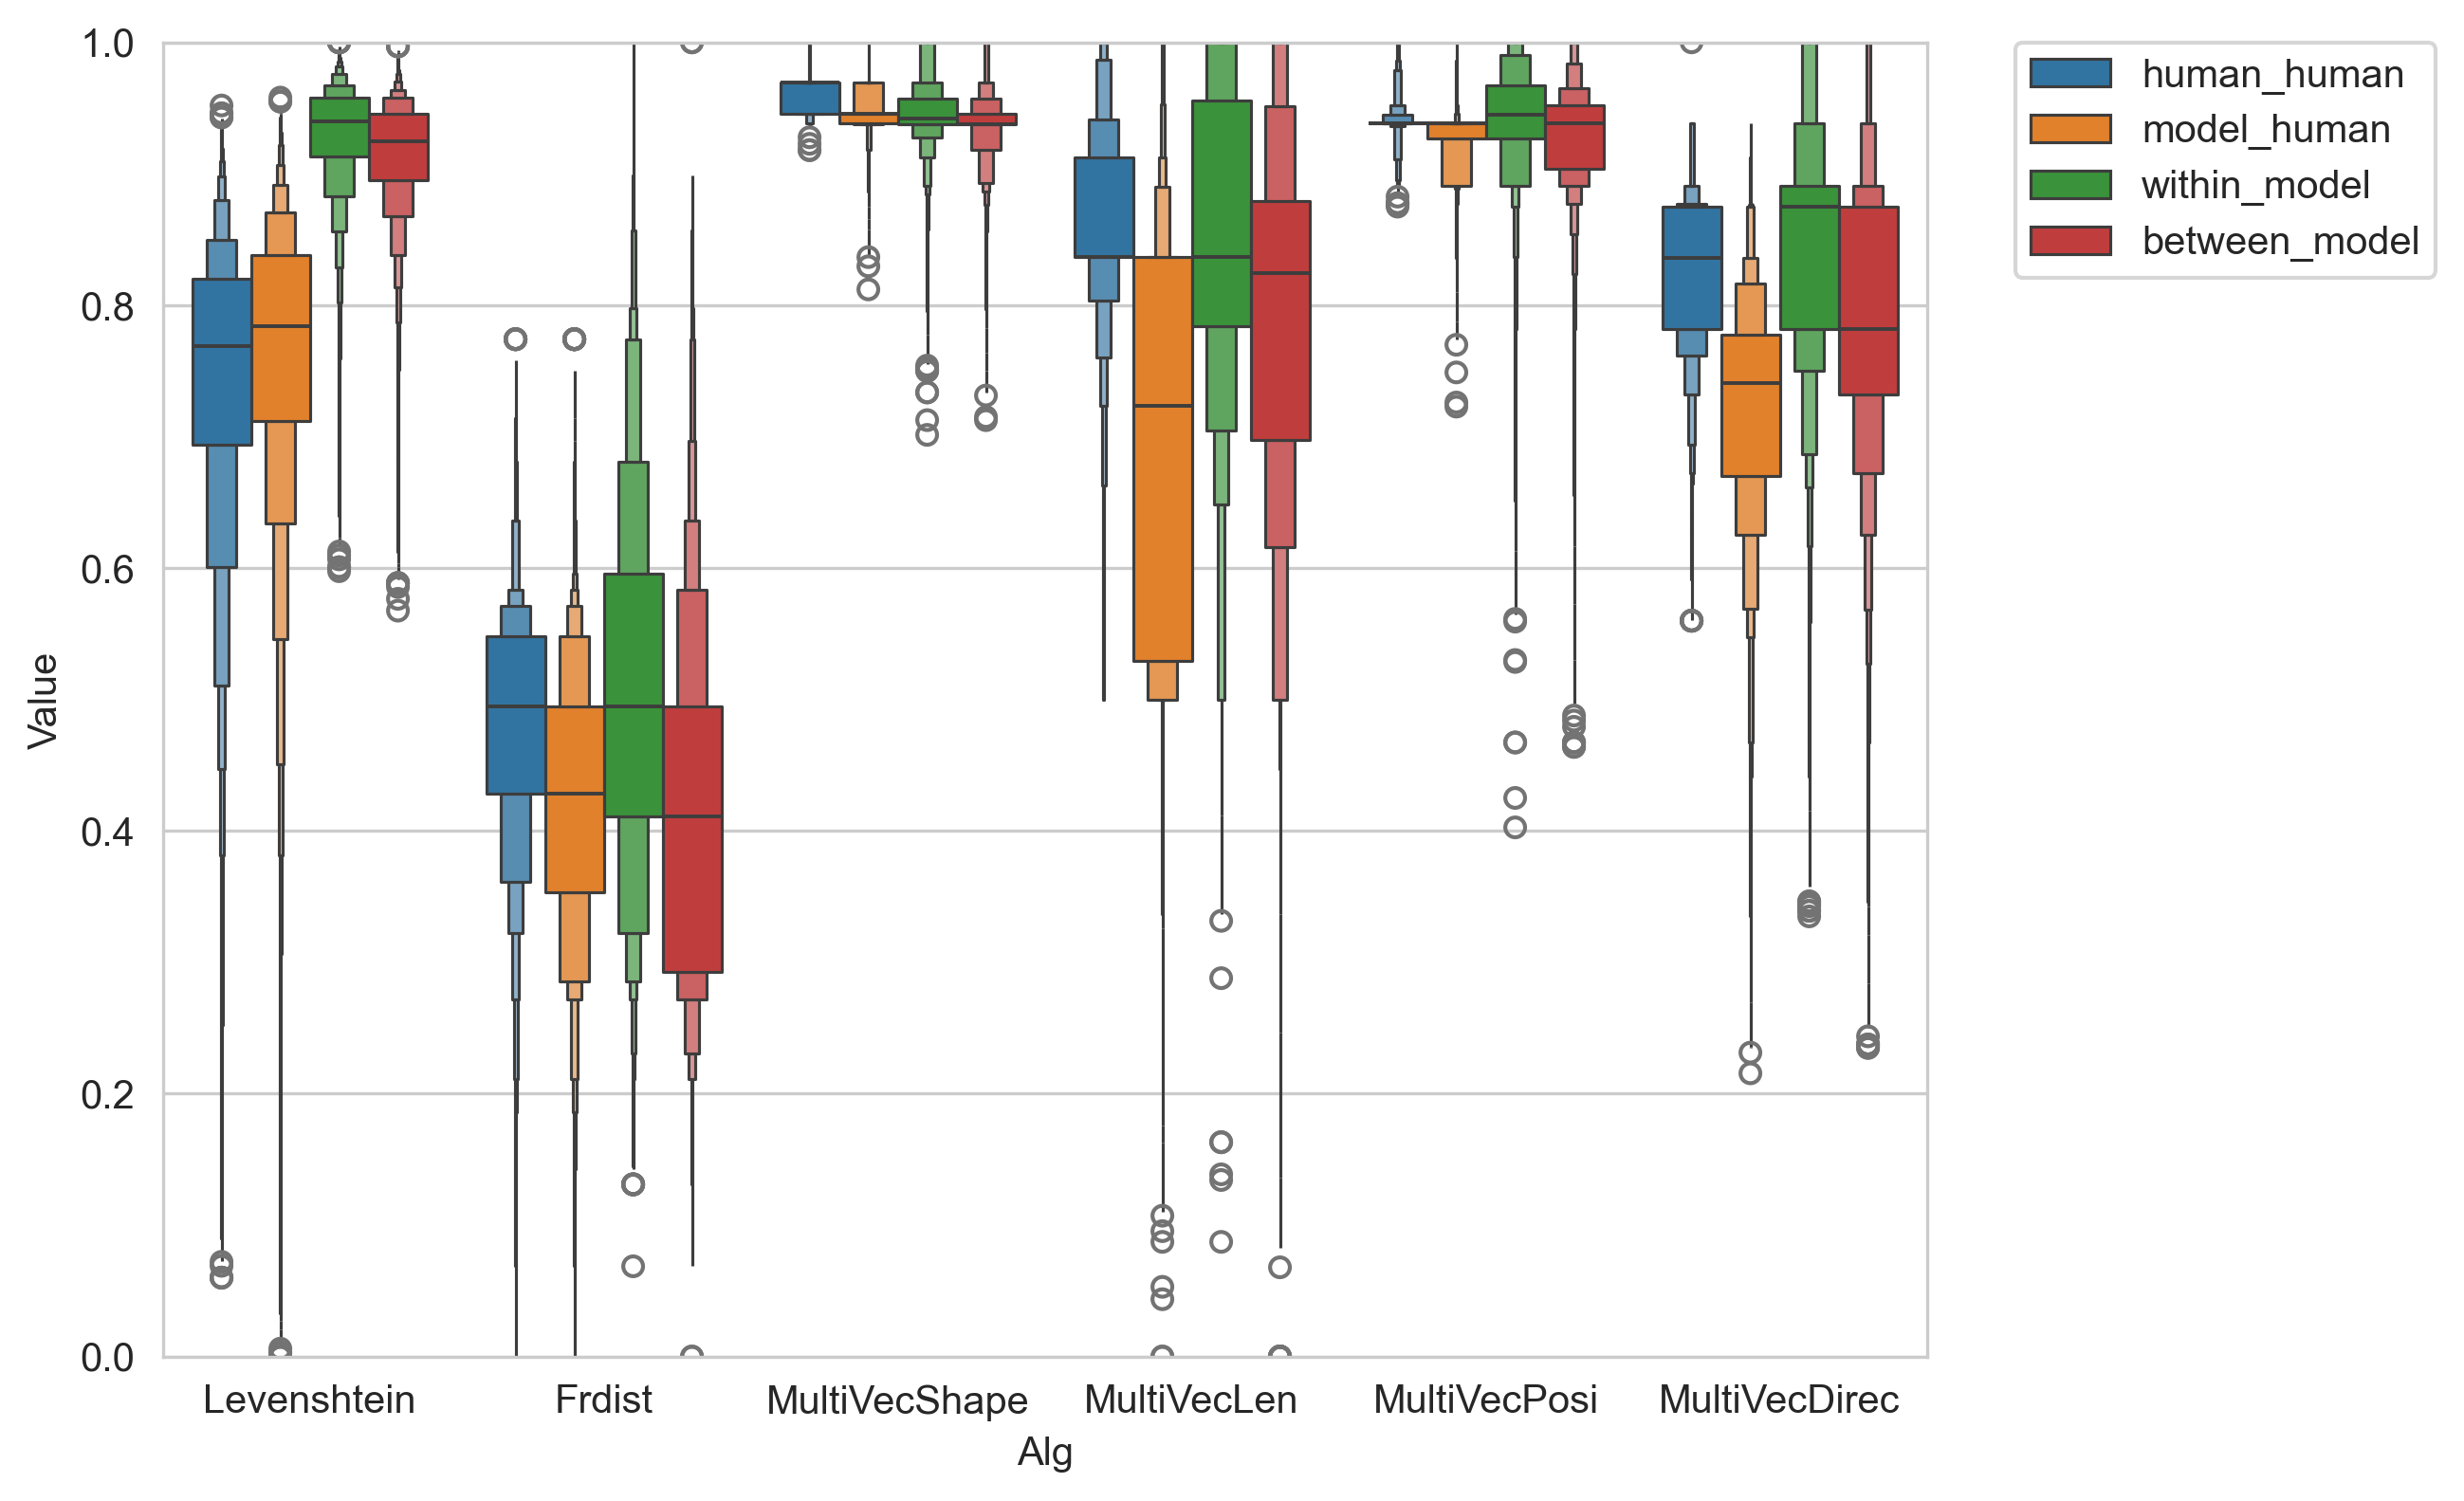

In [95]:
plt.figure(figsize=(8,6), dpi=300)  # Use before plotting  ### Standard version

sns.boxenplot(data=df, x='Alg', y='Value',hue='Cato',
            
            )
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.01, 0.2))
plt.show()

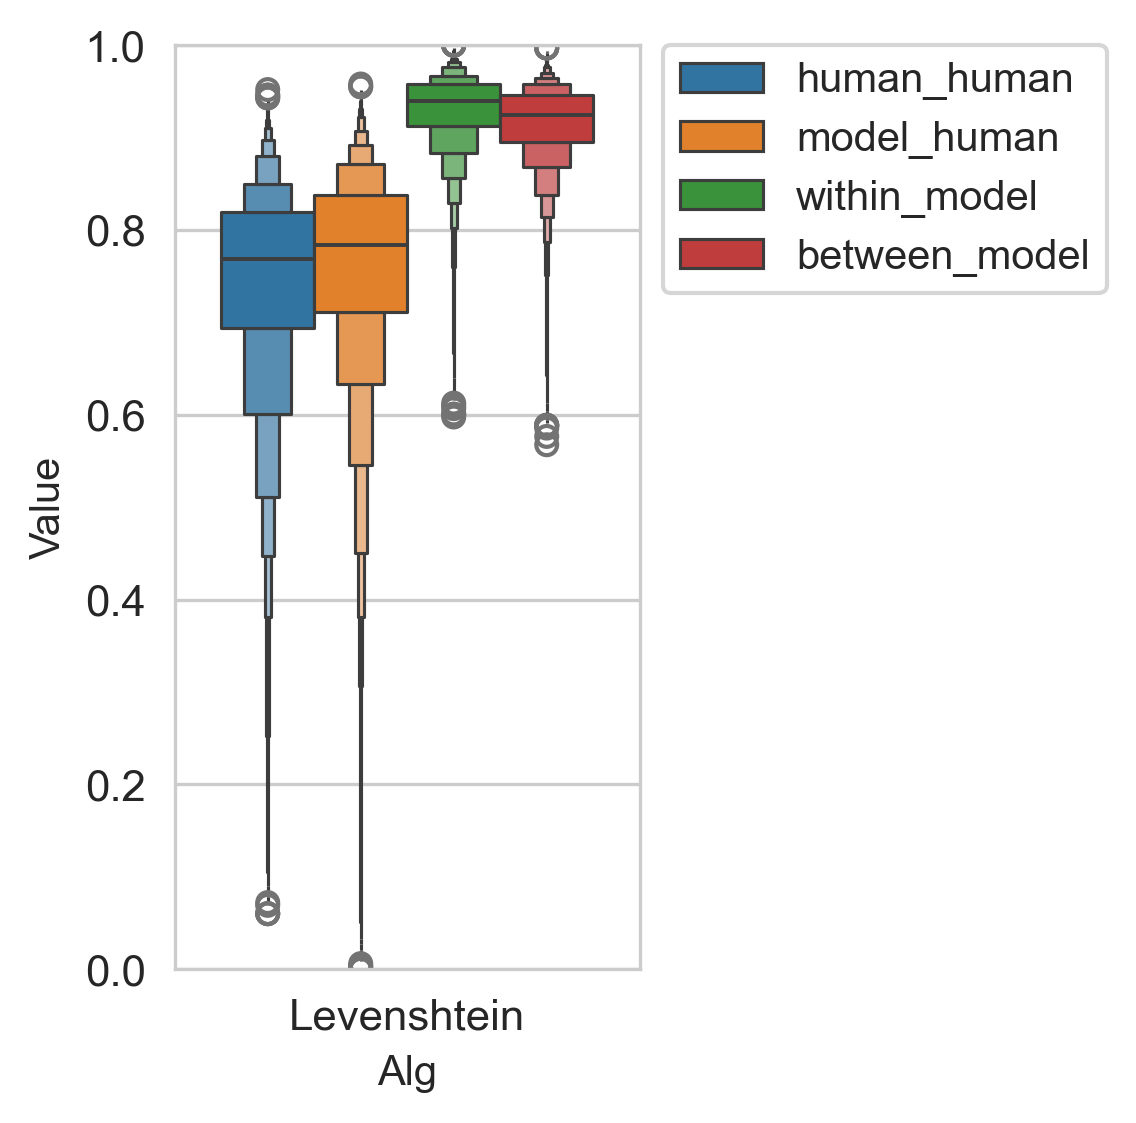

In [96]:
plt.figure(figsize=(2,4), dpi=300)  # Use before plotting  ### Composite figure version

ax = sns.boxenplot(data=df[df['Alg']=='Levenshtein'], x='Alg', y='Value',hue='Cato',
            
            )
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.01, 0.2))

# Adjust font size
ax.tick_params(axis='both', labelsize=10.5)
plt.show()

## Plot showing only model_human + Levenshtein (for assembling figures)

In [97]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
traj_compare = pd.read_csv('output/traj_compare.csv')
traj_compare_human = pd.read_csv('output/traj_compare_human.csv')
traj_compare_ai = pd.read_csv('output/traj_compare_ai.csv')

data1 = traj_compare[['Model', 'Task','Levenshtein','Frdist','MultiVecShape','MultiVecLen','MultiVecPosi','MultiVecDirec']].reset_index(drop=True)
data1.replace({'Model': {'gemini-3-pro': 'gemini', 'glm-4.6v': 'glm', 'gpt-5': 'gpt', 'hunyuan-t1-vision-20250916': 'hunyuan', 'qwen3-vl-8b-thinking': 'qwen'}}, inplace=True)

data1['Levenshtein'] = 1- data1['Levenshtein']/data1['Levenshtein'].max()
data1['Frdist'] = 1- data1['Frdist']/data1['Frdist'].max()
data1

,Model,Task,Levenshtein,Frdist,MultiVecShape,MultiVecLen,MultiVecPosi,MultiVecDirec
0,gemini,associate_attribute_1,0.795796,0.385548,0.938109,0.816034,0.936283,0.711580
1,gemini,associate_attribute_1,0.831832,0.361123,0.937500,0.663099,0.936283,0.625000
2,gemini,associate_attribute_1,0.801802,0.385548,0.937500,0.673803,0.908551,0.750000
3,gemini,associate_attribute_1,0.663664,0.385548,0.942122,0.500000,0.938717,0.782106
4,gemini,associate_attribute_1,0.810811,0.385548,0.937500,0.500000,0.938717,0.754869
...,...,...,...,...,...,...,...,...
110245,qwen,rank_time_1,0.786787,0.353187,0.945527,0.836901,0.938717,0.754869
110246,qwen,rank_time_1,0.729730,0.068685,0.945527,0.663099,0.938717,0.836013
110247,qwen,rank_time_1,0.783784,0.285714,0.945527,0.614200,0.938717,0.782106
110248,qwen,rank_time_1,0.402402,0.271569,0.938717,0.500000,0.938717,0.773652


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


<Figure size 640x480 with 0 Axes>

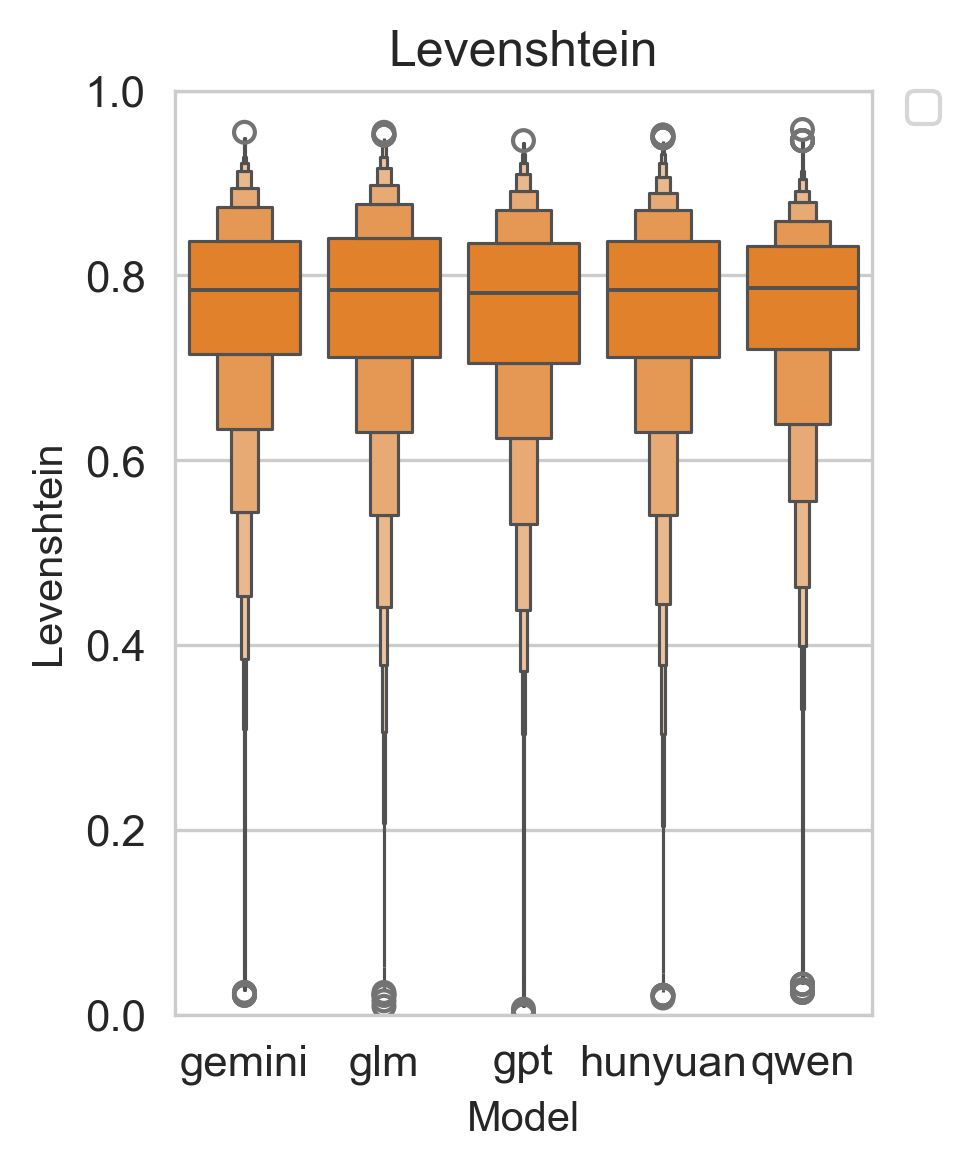

In [98]:
plt.cla()
plt.clf()
plt.figure(figsize=(3,4), dpi=300)  # Use before plotting
plt.title('Levenshtein')
ax = sns.boxenplot(data=data1, x='Model', y='Levenshtein',
              color='tab:orange',
            )
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)

plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.01, 0.2))

# Adjust font size
ax.tick_params(axis='both', labelsize=10.5)

plt.show()

# Boxenplots for each respondent
Note: In the data naming convention used in the code below, “_1_1” indicates a comparison between two correct trajectories, “_0_1” indicates a comparison between one correct and one incorrect trajectory, and “_0_0” indicates a comparison between two incorrect trajectories.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
traj_compare_human = pd.read_csv('output/traj_compare_human.csv')
all_code = pd.read_csv('data/all_code.csv')

df_correctness = all_code[all_code['Respondent'] == 'human'].drop_duplicates().reset_index(drop=True)
df_correctness['Participant1'] = df_correctness['Run']
df_correctness['Participant2'] = df_correctness['Run']
df = traj_compare_human.merge(df_correctness[['Task','Participant1','IsCorrect']], how='left',on=['Task','Participant1'])
df.rename(columns={'IsCorrect':'IsCorrect1'}, inplace=True)
df = df.drop_duplicates().reset_index(drop=True)
df = df.merge(df_correctness[['Task','Participant2','IsCorrect']], how='left',on=['Task','Participant2'])
df.rename(columns={'IsCorrect':'IsCorrect2'}, inplace=True)
df = df.drop_duplicates().reset_index(drop=True)
df['Cato'] = df['IsCorrect1'].astype(int).astype(str) + '_' + df['IsCorrect2'].astype(int).astype(str)
df.replace({'Cato': {'1_0': '0_1'}}, inplace=True)

df['Levenshtein'] = 1- df['Levenshtein']/df['Levenshtein'].max()
df['Frdist'] = 1- df['Frdist']/df['Frdist'].max()
df

In [5]:
df_human = df.drop(columns=['Participant1','Participant2','IsCorrect1','IsCorrect2'])

df_human = df_human.melt(id_vars=['Task','Cato'], var_name='Alg')
df_human['Cato'] = 'human_'+ df_human['Cato']
df_human

,Task,Cato,Alg,value
0,associate_attribute_1,human_1_1,Levenshtein,0.801917
1,associate_attribute_1,human_0_1,Levenshtein,0.792332
2,associate_attribute_1,human_0_1,Levenshtein,0.696486
3,associate_attribute_1,human_1_1,Levenshtein,0.782748
4,associate_attribute_1,human_0_1,Levenshtein,0.747604
...,...,...,...,...
105835,rank_time_1,human_1_1,MultiVecDirec,0.816152
105836,rank_time_1,human_1_1,MultiVecDirec,0.875000
105837,rank_time_1,human_1_1,MultiVecDirec,0.773652
105838,rank_time_1,human_1_1,MultiVecDirec,0.782106


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
traj_compare_ai = pd.read_csv('output/traj_compare_ai.csv')
all_traj = pd.read_csv('output/all_traj.csv')

ai_traj = all_traj[all_traj['Respondent']!='human']

ai_traj['Model_Run1'] = ai_traj['Respondent'] + '_' + ai_traj['Run']
ai_traj['Model_Run2'] = ai_traj['Model_Run1']
ai_traj

df = traj_compare_ai.merge(ai_traj[['Task','Model_Run1','IsCorrect']], how='left',on=['Task','Model_Run1'])
df.rename(columns={'IsCorrect':'IsCorrect1'}, inplace=True)

df = df.merge(ai_traj[['Task','Model_Run2','IsCorrect']], how='left',on=['Task','Model_Run2'])
df.rename(columns={'IsCorrect':'IsCorrect2'}, inplace=True)

df['Cato'] = df['IsCorrect1'].astype(str) + '_' + df['IsCorrect2'].astype(str)
df.replace({'Cato': {'1_0': '0_1'}}, inplace=True)
df

df['Levenshtein'] = 1- df['Levenshtein']/df['Levenshtein'].max()
df['Frdist'] = 1- df['Frdist']/df['Frdist'].max()
df
df_ai = df.drop(columns=['IsCorrect1','IsCorrect2'])

df_ai = df_ai.melt(id_vars=['Model_Run1','Model_Run2','Task','Cato'], var_name='Alg')
df_ai['Model1'] = df_ai['Model_Run1'].str.split('_', n=1, expand=True)[0]
df_ai['Model2'] = df_ai['Model_Run2'].str.split('_', n=1, expand=True)[0]
df_ai = df_ai.drop(columns=['Model_Run1','Model_Run2'])
df_ai

C:\Users\17475\AppData\Local\Temp\ipykernel_30712\959299373.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ai_traj['Model_Run1'] = ai_traj['Respondent'] + '_' + ai_traj['Run']
C:\Users\17475\AppData\Local\Temp\ipykernel_30712\959299373.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ai_traj['Model_Run2'] = ai_traj['Model_Run1']


,Task,Cato,Alg,value,Model1,Model2
0,associate_attribute_1,0_1,Levenshtein,0.805556,gemini-3-pro,gemini-3-pro
1,associate_attribute_1,0_0,Levenshtein,0.826389,gemini-3-pro,gemini-3-pro
2,associate_attribute_1,0_1,Levenshtein,0.847222,gemini-3-pro,gemini-3-pro
3,associate_attribute_1,0_1,Levenshtein,0.805556,gemini-3-pro,gemini-3-pro
4,associate_attribute_1,0_0,Levenshtein,0.847222,gemini-3-pro,gemini-3-pro
...,...,...,...,...,...,...
1005745,rank_time_1,0_0,MultiVecDirec,0.559924,qwen3-vl-8b-thinking,qwen3-vl-8b-thinking
1005746,rank_time_1,0_0,MultiVecDirec,0.891053,qwen3-vl-8b-thinking,qwen3-vl-8b-thinking
1005747,rank_time_1,0_0,MultiVecDirec,0.553614,qwen3-vl-8b-thinking,qwen3-vl-8b-thinking
1005748,rank_time_1,0_0,MultiVecDirec,0.875000,qwen3-vl-8b-thinking,qwen3-vl-8b-thinking


In [7]:
# ============================Version listing all data================================================
data1 = df_ai[(df_ai['Model1']=='gemini-3-pro')&(df_ai['Model2']=='gemini-3-pro')]
data1['Cato'] = 'gemini_' + data1['Cato']
data1.drop(columns=['Model1','Model2'], inplace=True)
data2 = df_ai[(df_ai['Model1']=='gpt-5')&(df_ai['Model2']=='gpt-5')]
data2['Cato'] = 'gpt_' + data2['Cato']
data2.drop(columns=['Model1','Model2'], inplace=True)
data3 = df_ai[(df_ai['Model1']=='glm-4.6v')&(df_ai['Model2']=='glm-4.6v')]
data3['Cato'] = 'glm_' + data3['Cato']
data3.drop(columns=['Model1','Model2'], inplace=True)
data4 = df_ai[(df_ai['Model1']=='hunyuan-t1-vision-20250916')&(df_ai['Model2']=='hunyuan-t1-vision-20250916')]
data4['Cato'] = 'hunyuan_' + data4['Cato']
data4.drop(columns=['Model1','Model2'], inplace=True)
data5 = df_ai[(df_ai['Model1']=='qwen3-vl-8b-thinking')&(df_ai['Model2']=='qwen3-vl-8b-thinking')]
data5['Cato'] = 'qwen_' + data5['Cato']
data5.drop(columns=['Model1','Model2'], inplace=True)

data = pd.concat([df_human, data1, data2, data3, data4, data5], ignore_index=True)

data.rename(columns={'value': 'Value'}, inplace=True)
data

C:\Users\17475\AppData\Local\Temp\ipykernel_30712\1630165030.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data1['Cato'] = 'gemini_' + data1['Cato']
C:\Users\17475\AppData\Local\Temp\ipykernel_30712\1630165030.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data1.drop(columns=['Model1','Model2'], inplace=True)
C:\Users\17475\AppData\Local\Temp\ipykernel_30712\1630165030.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the document

,Task,Cato,Alg,Value
0,associate_attribute_1,human_1_1,Levenshtein,0.801917
1,associate_attribute_1,human_0_1,Levenshtein,0.792332
2,associate_attribute_1,human_0_1,Levenshtein,0.696486
3,associate_attribute_1,human_1_1,Levenshtein,0.782748
4,associate_attribute_1,human_0_1,Levenshtein,0.747604
...,...,...,...,...
301585,rank_time_1,qwen_0_0,MultiVecDirec,0.559924
301586,rank_time_1,qwen_0_0,MultiVecDirec,0.891053
301587,rank_time_1,qwen_0_0,MultiVecDirec,0.553614
301588,rank_time_1,qwen_0_0,MultiVecDirec,0.875000


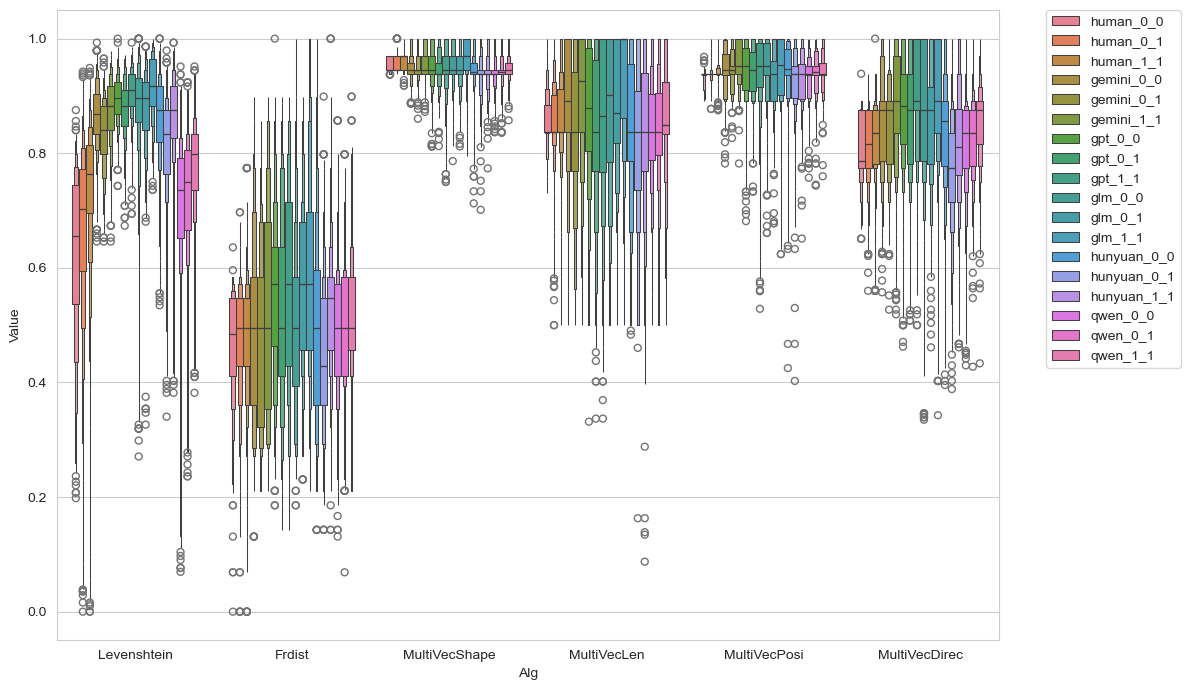

In [8]:
plt.figure(figsize=(12,7))  # Use before plotting
sns.boxenplot(data=data, x='Alg', y='Value',hue='Cato',
                hue_order=['human_0_0', 'human_0_1', 'human_1_1',
                            'gemini_0_0','gemini_0_1','gemini_1_1',
                           'gpt_0_0','gpt_0_1','gpt_1_1',
                           'glm_0_0','glm_0_1','glm_1_1',
                           'hunyuan_0_0','hunyuan_0_1','hunyuan_1_1',
                           'qwen_0_0','qwen_0_1','qwen_1_1',
                           ]
            )
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()

In [9]:
# ============================Version combining all LLMs by 0_0, 0_1, and 1_1 groups==========================
data = df_ai.copy()
data['Cato'] = 'model_' + data['Cato']
data.drop(columns=['Model1', 'Model2'], inplace=True)

data = pd.concat([df_human, data], ignore_index=True)
data = data.rename(columns={'value': 'Value'})
data

,Task,Cato,Alg,Value
0,associate_attribute_1,human_1_1,Levenshtein,0.801917
1,associate_attribute_1,human_0_1,Levenshtein,0.792332
2,associate_attribute_1,human_0_1,Levenshtein,0.696486
3,associate_attribute_1,human_1_1,Levenshtein,0.782748
4,associate_attribute_1,human_0_1,Levenshtein,0.747604
...,...,...,...,...
1111585,rank_time_1,model_0_0,MultiVecDirec,0.559924
1111586,rank_time_1,model_0_0,MultiVecDirec,0.891053
1111587,rank_time_1,model_0_0,MultiVecDirec,0.553614
1111588,rank_time_1,model_0_0,MultiVecDirec,0.875000


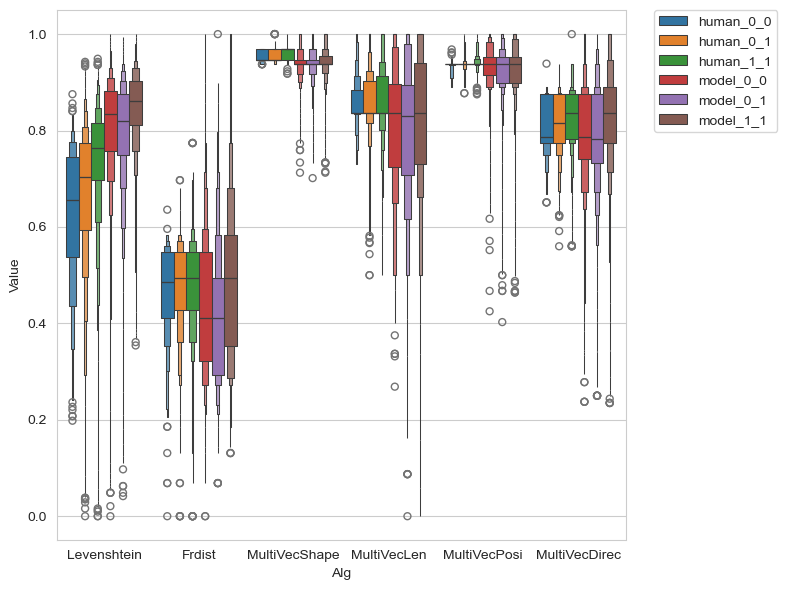

In [10]:
plt.figure(figsize=(8,6))  # Use before plotting
sns.boxenplot(data=data, x='Alg', y='Value',hue='Cato',
                hue_order=['human_0_0', 'human_0_1', 'human_1_1',
                            'model_0_0','model_0_1','model_1_1'
                           ]
            )
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()